# Clase 2: tablas dinámicas, visualización e interpretación de datos
Alumna: Angela Torres

**Duración:** 180 minutos (3 horas reloj)  
**Modalidad:** explicación, demostración, práctica guiada y desafío integrador  
**Herramientas:** Python, Pandas y Matplotlib  
**Dataset:** ventas de una librería escolar, incluido en el notebook

## Objetivos de aprendizaje

Al finalizar la clase, el estudiante será capaz de:

- construir tablas dinámicas mediante `pivot_table()`;
- elaborar tablas de frecuencias con `pd.crosstab()`;
- seleccionar gráficos adecuados para diferentes preguntas;
- crear y personalizar gráficos con Pandas y Matplotlib;
- interpretar tablas y gráficos sin confundir observaciones con opiniones;
- comunicar hallazgos mediante un miniinforme basado en datos.



## 1. Inicio: una decisión basada en datos 
La librería escolar ya corrigió errores y resumió sus ventas. Ahora la administración debe decidir:

> ¿Qué productos debería promocionar en cada sucursal y cómo podemos explicar la decisión de manera clara?

Una lista extensa de números puede ser correcta, pero difícil de interpretar. Las **tablas dinámicas** reorganizan los datos y los **gráficos** hacen visibles las comparaciones, proporciones y tendencias.

### Preguntas para conversar

1. ¿Es lo mismo registrar muchas operaciones que obtener mayor facturación?
La facturación depende del importe de cada operación.
2. ¿Qué resulta más fácil de comprender: 100 filas o un gráfico resumido?
Un gráfico resumido facilita comparar valores, mientras que la tabla detallada sirve para consultar cada registro.
3. ¿Un gráfico bonito siempre representa correctamente la información?
La claridad depende de elegir una escala, unidades y un tipo de gráfico adecuados.

### Ruta del análisis

En la clase anterior llegamos hasta la agrupación. Hoy completaremos la comunicación de resultados:

1. Datos originales.
2. Limpieza.
3. Análisis exploratorio.
4. Agrupación y resumen.
5. Tablas comparativas.
6. Visualización.
7. Interpretación y decisiones.

In [8]:
# Importación de las herramientas necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
plt.style.use('seaborn-v0_8-whitegrid')

### Dataset de continuidad

La siguiente celda genera y deja limpio el dataset utilizado en la clase anterior. Así todos podrán trabajar sin depender de archivos externos. Cada fila representa una operación de venta.

In [9]:
rng = np.random.default_rng(2026)
n = 120
productos = np.array(['Cuaderno', 'Bolígrafo', 'Carpeta', 'Regla', 'Mochila', 'Calculadora'])
categorias = {
    'Cuaderno': 'Papelería', 'Bolígrafo': 'Papelería',
    'Carpeta': 'Papelería', 'Regla': 'Útiles',
    'Mochila': 'Accesorios', 'Calculadora': 'Tecnología'
}
precios = {
    'Cuaderno': 18000, 'Bolígrafo': 5000, 'Carpeta': 12000,
    'Regla': 7000, 'Mochila': 95000, 'Calculadora': 65000
}
producto = rng.choice(productos, size=n, p=[0.25, 0.23, 0.16, 0.12, 0.10, 0.14])
df_limpio = pd.DataFrame({
    'fecha': pd.to_datetime('2026-03-01') + pd.to_timedelta(rng.integers(0, 92, size=n), unit='D'),
    'producto': producto,
    'categoria': [categorias[p] for p in producto],
    'cantidad': rng.integers(1, 8, size=n),
    'precio_unitario': [precios[p] for p in producto],
    'sucursal': rng.choice(['Centro', 'Terminal', 'Mercado'], size=n),
    'vendedor': rng.choice(['Ana', 'Carlos', 'Lucía', 'Miguel'], size=n)
})
df_limpio['total_venta'] = df_limpio['cantidad'] * df_limpio['precio_unitario']
df_limpio['mes'] = df_limpio['fecha'].dt.month
df_limpio['nombre_mes'] = df_limpio['mes'].map({3: 'Marzo', 4: 'Abril', 5: 'Mayo'})
df_limpio.head()

,fecha,producto,categoria,cantidad,precio_unitario,sucursal,vendedor,total_venta,mes,nombre_mes
0,2026-05-30,Cuaderno,Papelería,4,18000,Terminal,Miguel,72000,5,Mayo
1,2026-04-30,Carpeta,Papelería,6,12000,Mercado,Lucía,72000,4,Abril
2,2026-05-31,Bolígrafo,Papelería,2,5000,Centro,Carlos,10000,5,Mayo
3,2026-05-21,Bolígrafo,Papelería,6,5000,Mercado,Carlos,30000,5,Mayo
4,2026-05-08,Bolígrafo,Papelería,2,5000,Mercado,Miguel,10000,5,Mayo


### Activación de conocimientos previos

Antes de avanzar, responda usando Pandas:

1. ¿Cuántas filas y columnas tiene el dataset?
2. ¿Cuál es la facturación total?
3. ¿Qué sucursal tiene mayor facturación?
4. ¿Qué diferencia existe entre `groupby()` y un filtro?

In [10]:
# Escriba aquí sus respuestas de recuperación
# ¿Cuántas filas y columnas tiene el dataset?

filas, columnas = df_limpio.shape

print("Filas:", filas)
print("Columnas:", columnas)

Filas: 120
Columnas: 10


In [11]:
#2. ¿Cuál es la facturación total?
facturacion_total = df_limpio["total_venta"].sum()

print("Facturación total:", facturacion_total)

Facturación total: 11396000


In [12]:
#3. ¿Qué sucursal tiene mayor facturación?
facturacion_sucursal = df_limpio.groupby("sucursal")["total_venta"].sum()

sucursal_mayor = facturacion_sucursal.idxmax()

print("Sucursal con mayor facturación:", sucursal_mayor)

Sucursal con mayor facturación: Centro


4. ¿Qué diferencia existe entre `groupby()` y un filtro?

La diferencia es que groupby agrupa datos por columnas y luego permite realizar operaciones sobre esas columnas, mientras que un filtro es para seleccionar las filas que cumplen x condicion


## 2. Tablas dinámicas con `pivot_table()` 

### Concepto principal

Una **tabla dinámica** resume una gran cantidad de registros y permite compararlos mediante filas y columnas.

Su estructura básica es:

```python
pd.pivot_table(
    datos,
    values='columna_numerica',
    index='filas',
    columns='columnas',
    aggfunc='operacion',
    fill_value=0
)
```

| Parámetro | Función |
|---|---|
| `values` | Indica qué valores numéricos se resumirán |
| `index` | Define las categorías que aparecerán en las filas |
| `columns` | Define las categorías que aparecerán en las columnas |
| `aggfunc` | Establece la operación: suma, promedio, conteo, etc. |
| `fill_value` | Reemplaza combinaciones vacías, normalmente por cero |

### Ejemplo 1: facturación por sucursal y categoría

Pregunta: **¿Cuánto facturó cada categoría en cada sucursal?**

In [13]:
tabla_sucursal_categoria = pd.pivot_table(
    df_limpio,
    values='total_venta',
    index='sucursal',
    columns='categoria',
    aggfunc='sum',
    fill_value=0
)
tabla_sucursal_categoria

categoria,Accesorios,Papelería,Tecnología,Útiles
sucursal,,,,
Centro,1710000,1367000,845000,196000
Mercado,1045000,1527000,1170000,98000
Terminal,1045000,844000,1430000,119000


### Cómo leer la tabla

- Una **fila** contiene los resultados de una sucursal.
- Una **columna** contiene los resultados de una categoría.
- Cada **celda** es la suma de `total_venta` de esa combinación.
- El cero indica que no hubo registros para la combinación.

No basta con mostrar la tabla: debemos convertir sus números en afirmaciones verificables.

### Ejemplo 2: unidades vendidas por producto y mes


In [14]:
tabla_producto_mes = pd.pivot_table(
    df_limpio, values='cantidad', index='producto', columns='nombre_mes',
    aggfunc='sum', fill_value=0
).reindex(columns=['Marzo', 'Abril', 'Mayo'])
tabla_producto_mes

nombre_mes,Marzo,Abril,Mayo
producto,,,
Bolígrafo,49,24,35
Calculadora,28,13,12
Carpeta,55,43,35
Cuaderno,37,27,25
Mochila,10,17,13
Regla,7,24,28


### Ejemplo 3: promedio y totales generales

`margins=True` agrega una fila y una columna de totales. Aquí calculamos el promedio de cada operación, no la suma.

In [15]:
promedio_vendedor_sucursal = pd.pivot_table(
    df_limpio, values='total_venta', index='vendedor', columns='sucursal',
    aggfunc='mean', fill_value=0, margins=True, margins_name='Promedio general'
).round(2)
promedio_vendedor_sucursal

sucursal,Centro,Mercado,Terminal,Promedio general
vendedor,,,,
Ana,"140,750.00","110,333.33","187,000.00","133,250.00"
Carlos,"67,352.94","60,000.00","101,666.67","78,939.39"
Lucía,"32,083.33","109,916.67","48,857.14","66,000.00"
Miguel,"146,200.00","79,750.00","112,800.00","110,843.75"
Promedio general,"87,617.02","96,000.00","104,181.82","94,966.67"


### Ejemplo 4: varias operaciones en una tabla

También podemos solicitar más de una función de resumen.

In [16]:
tabla_multiple = pd.pivot_table(
    df_limpio, values='total_venta', index='categoria',
    aggfunc=['sum', 'mean', 'count']
).round(2)
tabla_multiple

,sum,mean,count
,total_venta,total_venta,total_venta
categoria,,,
Accesorios,3800000,"422,222.22",9
Papelería,3738000,"44,500.00",84
Tecnología,3445000,"229,666.67",15
Útiles,413000,"34,416.67",12


### `groupby()` frente a `pivot_table()`

| Herramienta | Conviene usarla cuando... |
|---|---|
| `groupby()` | Necesitamos agrupar y producir una serie o tabla lineal |
| `pivot_table()` | Necesitamos comparar dos categorías en filas y columnas |

Ambas pueden obtener resultados equivalentes. La diferencia principal está en la forma de organizar la salida.

## 3. Práctica guiada 1 

Resuelva los siguientes ejercicios. Debajo de cada resultado escriba una oración interpretativa.

1. Cree una tabla con la **facturación total por vendedor y mes**.
2. Cree una tabla con las **unidades vendidas por sucursal y producto**.
3. Calcule el **promedio de venta por categoría y sucursal**.
4. Repita el ejercicio 1 incluyendo totales mediante `margins=True`.
5. Identifique, observando sus tablas, qué vendedor facturó más y qué combinación producto-sucursal vendió más unidades.

In [17]:
# Ejercicio 1: facturación total por vendedor y mes
ventas_vendedor_mes = df_limpio.pivot_table(
    index="vendedor",
    columns="nombre_mes",
    values="total_venta",
    aggfunc="sum",
    fill_value=0
)

ventas_vendedor_mes


nombre_mes,Abril,Marzo,Mayo
vendedor,,,
Ana,1857000,556000,785000
Carlos,403000,1361000,841000
Lucía,484000,468000,1094000
Miguel,1006000,2005000,536000


In [18]:
# Ejercicio 2: unidades vendidas por sucursal y producto
unidades_sucursal_producto = df_limpio.pivot_table(
    index="sucursal",
    columns="producto",
    values="cantidad",
    aggfunc="sum",
    fill_value=0
)

unidades_sucursal_producto

producto,Bolígrafo,Calculadora,Carpeta,Cuaderno,Mochila,Regla
sucursal,,,,,,
Centro,43,13,45,34,18,28
Mercado,45,18,50,39,11,14
Terminal,20,22,38,16,11,17


In [19]:
# Ejercicios 3 y 4
promedio_categoria_sucursal = (
    df_limpio.groupby(["categoria", "sucursal"])["total_venta"]
    .mean()
    .unstack(fill_value=0)
    .round(2)
)

promedio_categoria_sucursal



facturacion_con_totales = df_limpio.pivot_table(
    index="vendedor",
    columns="nombre_mes",
    values="total_venta",
    aggfunc="sum",
    fill_value=0,
    margins=True,
    margins_name="Total general"
)

facturacion_con_totales


nombre_mes,Abril,Marzo,Mayo,Total general
vendedor,,,,
Ana,1857000,556000,785000,3198000
Carlos,403000,1361000,841000,2605000
Lucía,484000,468000,1094000,2046000
Miguel,1006000,2005000,536000,3547000
Total general,3750000,4390000,3256000,11396000


### Interpretación de la práctica

- Hallazgo 1: El vendedor que facturó más fue Miguel
- Hallazgo 2: Lo que más de vendió fue la carpeta en el mercado
- Evidencia numérica utilizada:

In [20]:
total_por_vendedor = df_limpio.groupby("vendedor")["total_venta"].sum()
mejor_vendedor = total_por_vendedor.idxmax()

unidades_producto_sucursal = (
    df_limpio.groupby(["producto", "sucursal"])["cantidad"]
    .sum()
)

mejor_combinacion = unidades_producto_sucursal.idxmax()

print("Vendedor que más facturó:", mejor_vendedor)
print("Producto y sucursal con más unidades:", mejor_combinacion)

Vendedor que más facturó: Miguel
Producto y sucursal con más unidades: ('Carpeta', 'Mercado')


## 4. Tablas de frecuencia con `pd.crosstab()` 

Una **tabla de frecuencia cruzada** cuenta cuántas veces aparece cada combinación de dos variables categóricas.

Pregunta: **¿Cuántas operaciones registró cada vendedor en cada sucursal?**

In [21]:
frecuencia_vendedor_sucursal = pd.crosstab(
    df_limpio['vendedor'],
    df_limpio['sucursal'],
    margins=True,
    margins_name='Total'
)
frecuencia_vendedor_sucursal

sucursal,Centro,Mercado,Terminal,Total
vendedor,,,,
Ana,8,12,4,24
Carlos,17,4,12,33
Lucía,12,12,7,31
Miguel,10,12,10,32
Total,47,40,33,120


### Frecuencias porcentuales

Con `normalize='index'` cada fila suma 100 %. Esto ayuda a comparar distribuciones aunque los vendedores tengan distinta cantidad de operaciones.

In [22]:
porcentaje_vendedor_sucursal = pd.crosstab(
    df_limpio['vendedor'], df_limpio['sucursal'], normalize='index'
) * 100
porcentaje_vendedor_sucursal.round(1)

sucursal,Centro,Mercado,Terminal
vendedor,,,
Ana,33.30,50.00,16.70
Carlos,51.50,12.10,36.40
Lucía,38.70,38.70,22.60
Miguel,31.20,37.50,31.20


### Diferencia fundamental

- `crosstab()` responde normalmente **cuántos registros existen**.
- `pivot_table()` responde normalmente **cuánto suman, promedian o representan los valores**.

Una persona puede aparecer en muchas operaciones pequeñas y, aun así, no ser quien más facturó.

### Práctica guiada 2

1. Construya una tabla de frecuencias entre `producto` y `sucursal`.
2. Agregue los totales.
3. Obtenga porcentajes por fila.
4. Explique por qué esta tabla no muestra directamente la facturación.

In [23]:
# Resuelva aquí la práctica guiada 2
# 1. Construya una tabla de frecuencias entre `producto` y `sucursal`.
frecuencia_producto = pd.crosstab(
    index=df_limpio["producto"],
    columns=df_limpio["sucursal"]
)

frecuencia_producto

sucursal,Centro,Mercado,Terminal
producto,,,
Bolígrafo,12,11,8
Calculadora,4,6,5
Carpeta,11,9,10
Cuaderno,9,9,5
Mochila,5,2,2
Regla,6,3,3


In [24]:
#2. Agregue los totales.
frecuencia_con_total = pd.crosstab(
    df_limpio["producto"],
    df_limpio["sucursal"],
    margins=True,
    margins_name="Total"
)

frecuencia_con_total

sucursal,Centro,Mercado,Terminal,Total
producto,,,,
Bolígrafo,12,11,8,31
Calculadora,4,6,5,15
Carpeta,11,9,10,30
Cuaderno,9,9,5,23
Mochila,5,2,2,9
Regla,6,3,3,12
Total,47,40,33,120


In [25]:
#3. Obtenga porcentajes por fila.
porcentaje_producto = (
    pd.crosstab(
        df_limpio["producto"],
        df_limpio["sucursal"],
        normalize="index"
    )
    .mul(100)
    .round(1)
)

porcentaje_producto

sucursal,Centro,Mercado,Terminal
producto,,,
Bolígrafo,38.70,35.50,25.80
Calculadora,26.70,40.00,33.30
Carpeta,36.70,30.00,33.30
Cuaderno,39.10,39.10,21.70
Mochila,55.60,22.20,22.20
Regla,50.00,25.00,25.00


# 4. Explique por qué esta tabla no muestra directamente la facturación.
La tabla no muestra directamente la facturación porque crosstab() cuenta la cantidad de operaciones, pero no suma el valor de totalventa

## Pausa activa y revisión 

Antes de continuar, complete verbalmente:

1. Una tabla dinámica sirve para resumir y comparar datos organizándolos en filas y columnas.
2. El parámetro aggfunc sirve para indicar qué operación queremos realizar sobre los datos, como suma, promedio o conteo.
3. crosstab() es útil cuando necesitamos contar cuántas veces aparece cada combinación de categorías.
4. Contar operaciones no es igual que sumar facturación porque una operación puede tener un valor diferente a otra, por lo que tener más operaciones no significa necesariamente haber facturado más.

## 5. Visualización de datos 
### Elegir el gráfico correcto

| Pregunta | Gráfico recomendado |
|---|---|
| ¿Qué categoría vende más? | Barras |
| ¿Cómo cambia la venta con el tiempo? | Líneas |
| ¿Qué proporción representa cada categoría? | Circular, con pocas categorías |
| ¿Cómo se comparan categorías entre sucursales? | Barras agrupadas o apiladas |

Un buen gráfico debe tener título claro, nombres de ejes, unidades, escala legible y colores que no confundan.

### Ejemplo 1: gráfico de barras para comparar categorías


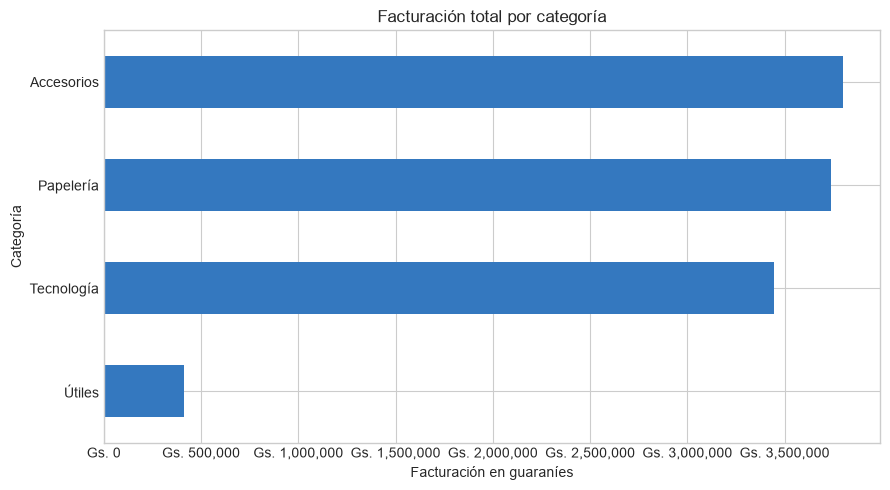

In [26]:
ventas_categoria = df_limpio.groupby('categoria')['total_venta'].sum().sort_values()
ax = ventas_categoria.plot(kind='barh', color='#3478BF', figsize=(9, 5))
ax.set_title('Facturación total por categoría')
ax.set_xlabel('Facturación en guaraníes')
ax.set_ylabel('Categoría')
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'Gs. {x:,.0f}'))
plt.tight_layout()
plt.show()

### Ejemplo 2: gráfico de líneas para observar cambios

Para una secuencia temporal debemos respetar el orden cronológico.

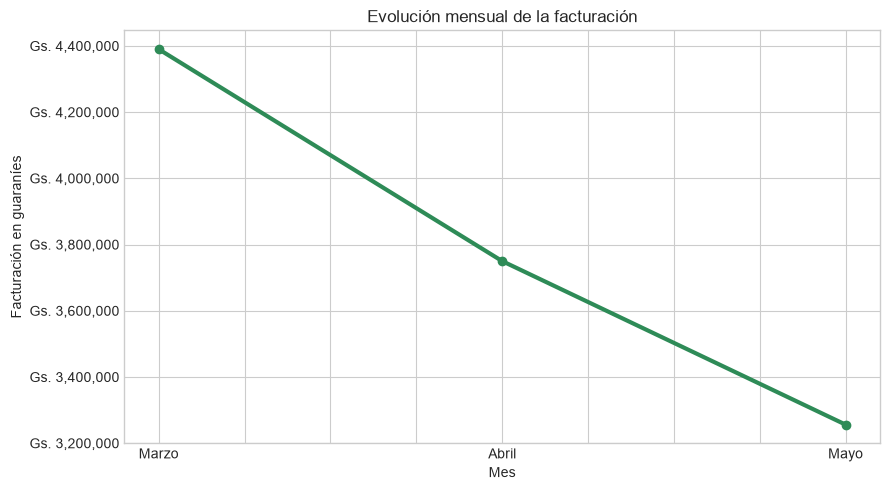

In [27]:
orden_meses = ['Marzo', 'Abril', 'Mayo']
ventas_mes = df_limpio.groupby('nombre_mes')['total_venta'].sum().reindex(orden_meses)
ax = ventas_mes.plot(kind='line', marker='o', linewidth=3, color='#2E8B57', figsize=(9, 5))
ax.set_title('Evolución mensual de la facturación')
ax.set_xlabel('Mes')
ax.set_ylabel('Facturación en guaraníes')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'Gs. {x:,.0f}'))
plt.tight_layout()
plt.show()

### Ejemplo 3: barras agrupadas a partir de una tabla dinámica


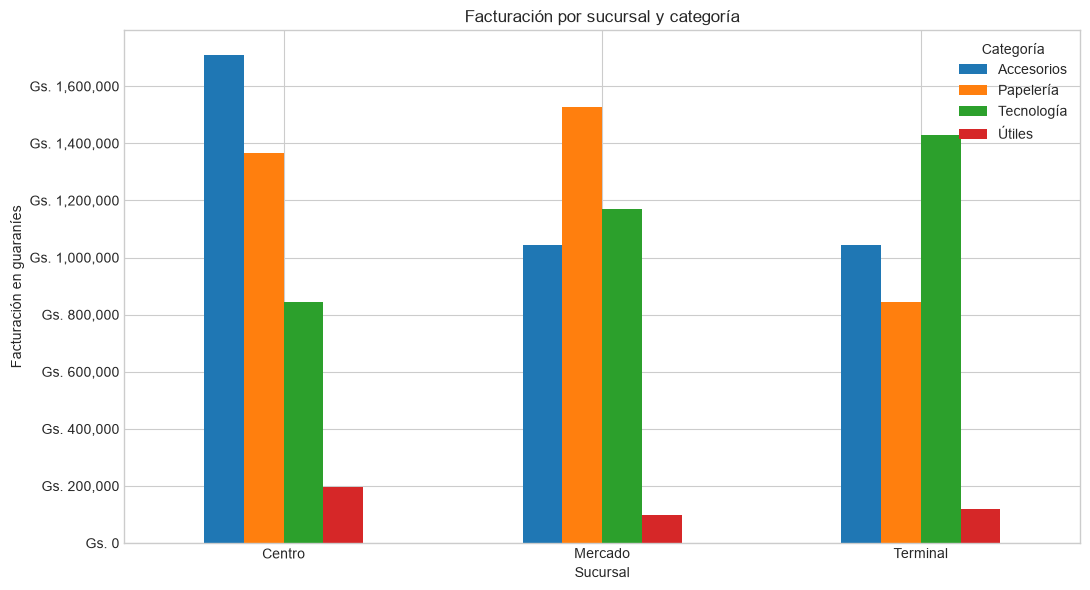

In [28]:
ax = tabla_sucursal_categoria.plot(kind='bar', figsize=(11, 6))
ax.set_title('Facturación por sucursal y categoría')
ax.set_xlabel('Sucursal')
ax.set_ylabel('Facturación en guaraníes')
ax.tick_params(axis='x', rotation=0)
ax.legend(title='Categoría')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'Gs. {x:,.0f}'))
plt.tight_layout()
plt.show()

### Ejemplo 4: gráfico circular y uso responsable

El gráfico circular funciona mejor con pocas categorías. Si hay demasiadas porciones, las comparaciones se vuelven difíciles.

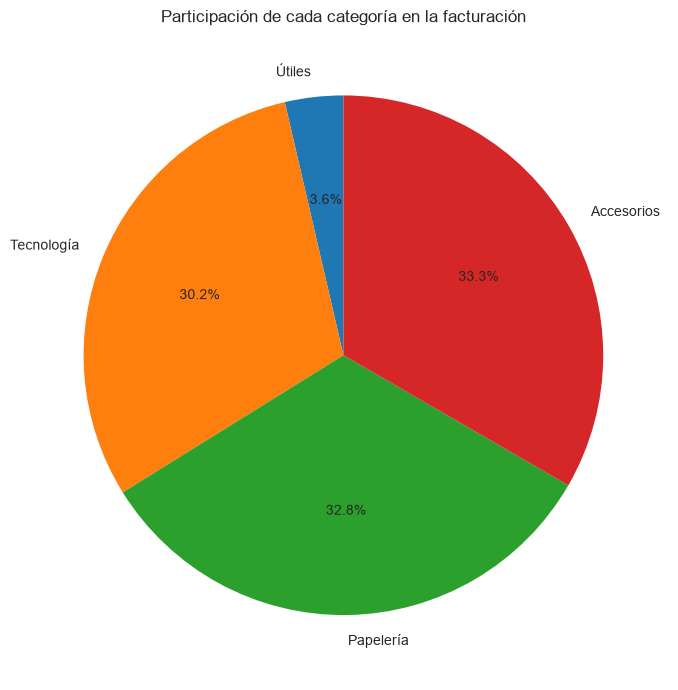

In [29]:
ventas_categoria.plot(
    kind='pie', autopct='%1.1f%%', startangle=90, figsize=(7, 7),
    ylabel='', title='Participación de cada categoría en la facturación'
)
plt.tight_layout()
plt.show()

### Errores frecuentes que debemos evitar

- usar un gráfico de líneas para categorías sin orden temporal;
- omitir títulos o unidades;
- recargar el gráfico con demasiados colores;
- utilizar un gráfico circular con demasiadas porciones;
- afirmar una causa cuando los datos solo muestran una diferencia;
- modificar la escala para exagerar cambios pequeños.

## 6. Práctica guiada 3: gráficos e interpretación 

Realice las siguientes actividades:

1. Calcule la facturación por producto y represéntela con barras horizontales.
2. Calcule la facturación mensual de cada vendedor y represéntela mediante líneas.
3. Represente las unidades vendidas por sucursal y producto con barras agrupadas.
4. Personalice títulos, nombres de ejes, colores y tamaño.
5. Debajo de cada gráfico escriba un hallazgo que incluya evidencia numérica.

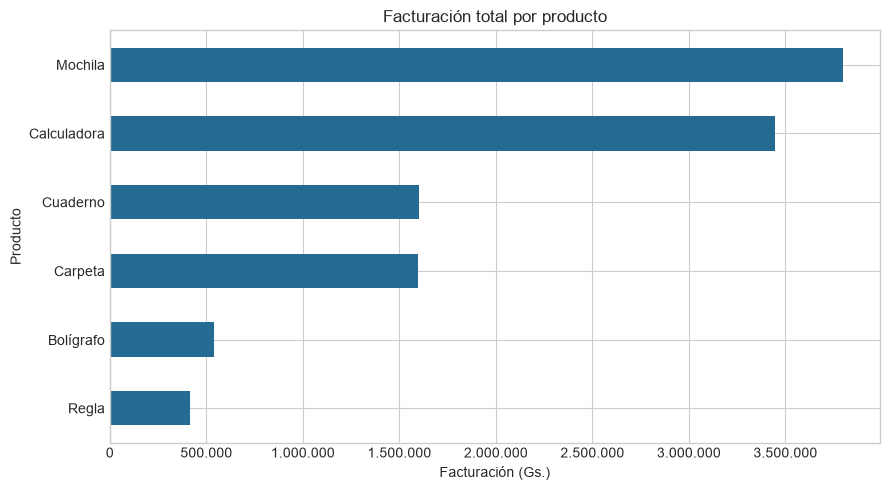

In [30]:
# Ejercicio gráfico 1: facturación por producto

facturacion_producto = df_limpio.groupby("producto")["total_venta"].sum().sort_values()
formato_gs = FuncFormatter(lambda valor, _: f"{valor:,.0f}".replace(",", "."))

ax = facturacion_producto.plot.barh(figsize=(9, 5), color="#246A92")
ax.set(title="Facturación total por producto", xlabel="Facturación (Gs.)", ylabel="Producto")
ax.xaxis.set_major_formatter(formato_gs)
plt.tight_layout()
plt.show()


**Interpretación del gráfico 1:**  
Mochila registro la mayor facturacion, con Gs. 3.800.000, seguida por
Calculadora, con Gs. 3.445.000


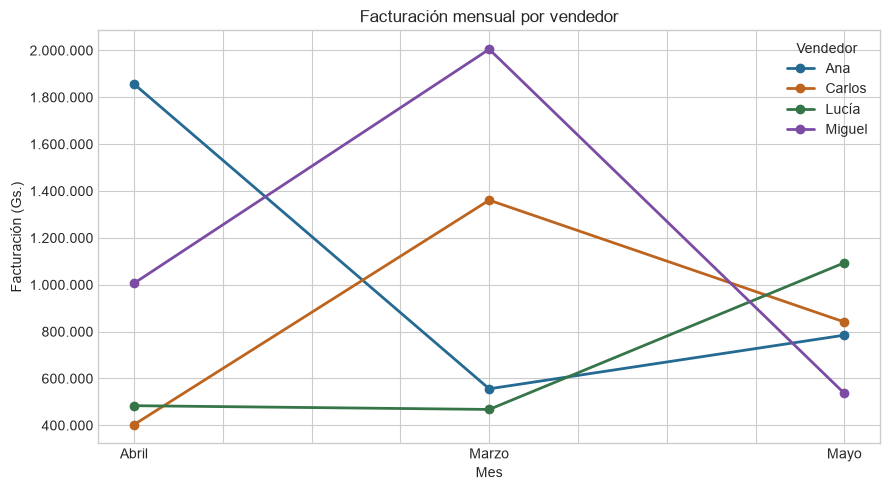

In [34]:
# Ejercicio gráfico 2: evolución mensual por vendedor

ax = ventas_vendedor_mes.T.plot.line(
    figsize=(9, 5), marker="o", linewidth=2,
    color=["#246A92", "#BD641E", "#367548", "#7C4CA4"]
)
ax.set(title="Facturación mensual por vendedor", xlabel="Mes", ylabel="Facturación (Gs.)")
ax.yaxis.set_major_formatter(formato_gs)
ax.legend(title="Vendedor")
plt.tight_layout()
plt.show()


**Interpretación del gráfico 2:**  
Miguel registro el mayor importe mensual de un vendedor, con Gs. 2.005.000 
en marzo. En abril facturo Gs. 1.006.000


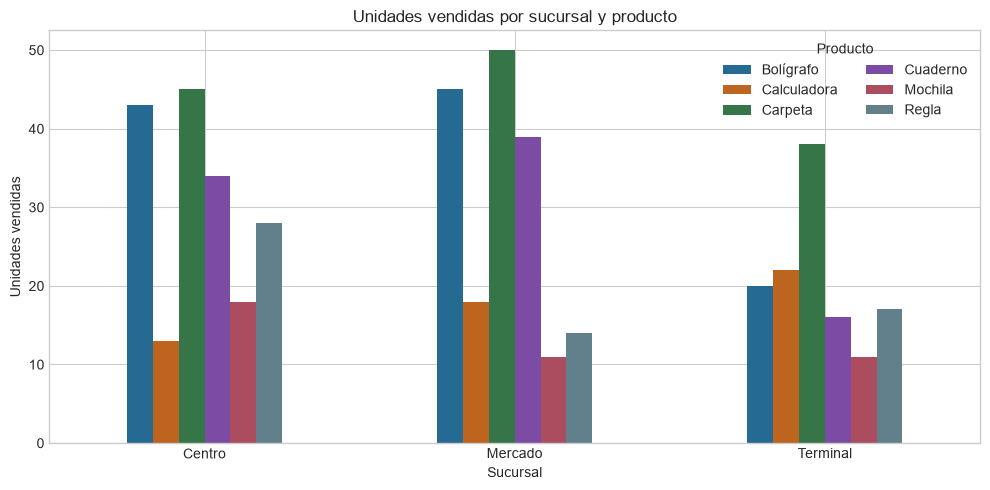

In [35]:
# Ejercicio gráfico 3: unidades por sucursal y producto

ax = unidades_sucursal_producto.plot.bar(
    figsize=(10, 5), color=["#246A92", "#BD641E", "#367548", "#7C4CA4", "#AB4D5F", "#61808C"]
)
ax.set(title="Unidades vendidas por sucursal y producto", xlabel="Sucursal", ylabel="Unidades vendidas")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Producto", ncol=2)
plt.tight_layout()
plt.show()


**Interpretación del gráfico 3:**  
Carpeta en Mercado lidero con 50 unidades, frente a 45 en Centro y 38 en Terminal para el mismo producto


## 7. Cómo interpretar correctamente 

Una conclusión sólida contiene tres elementos:

1. **Hallazgo:** qué se observa.
2. **Evidencia:** número o comparación que lo demuestra.
3. **Implicación:** por qué puede ser importante.

### Modelo

> La categoría Tecnología presenta la mayor facturación, con Gs. X. Esto indica que, aunque no necesariamente tenga más operaciones, sus ventas aportan una parte importante de los ingresos.

Observe que no afirmamos la causa. Para decir *por qué* ocurrió necesitaríamos otros datos o una investigación adicional.

## 8. Desafío integrador: miniinforme gerencial 

La administración solicita un informe breve para orientar una campaña comercial. Prepare lo siguiente:

1. Una tabla dinámica de facturación por sucursal y categoría.
2. Una tabla de frecuencia de operaciones por vendedor y sucursal.
3. Un gráfico de barras que permita comparar productos.
4. Un gráfico de líneas que muestre la evolución mensual.
5. Tres conclusiones respaldadas por números.
6. Dos recomendaciones concretas para la librería.

### Criterios de logro

| Criterio | Puntaje |
|---|---:|
| Tablas correctas y legibles | 3 |
| Gráficos adecuados y personalizados | 3 |
| Conclusiones con evidencia | 2 |
| Recomendaciones coherentes | 2 |
| **Total** | **10** |

#### Facturación por sucursal y categoría (Gs.)

categoria,Accesorios,Papelería,Tecnología,Útiles
sucursal,,,,
Centro,1710000,1367000,845000,196000
Mercado,1045000,1527000,1170000,98000
Terminal,1045000,844000,1430000,119000


#### Operaciones por vendedor y sucursal

sucursal,Centro,Mercado,Terminal,Total
vendedor,,,,
Ana,8,12,4,24
Carlos,17,4,12,33
Lucía,12,12,7,31
Miguel,10,12,10,32
Total,47,40,33,120


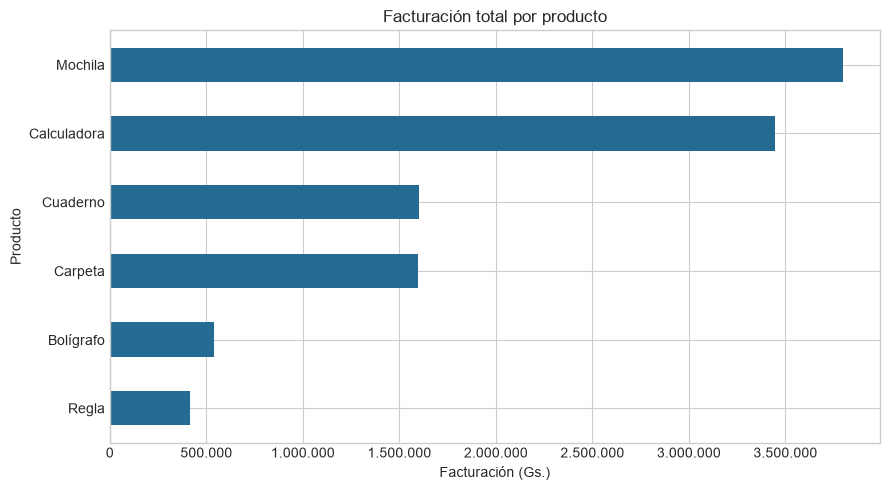

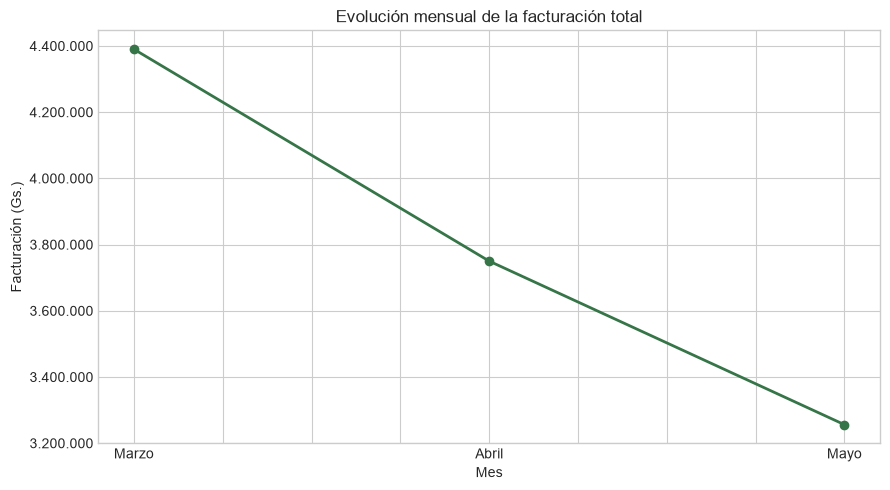

In [38]:
# Desarrolle aquí las tablas y los gráficos del desafío integrador
from IPython.display import Markdown, display

display(Markdown("#### Facturación por sucursal y categoría (Gs.)"))
display(tabla_sucursal_categoria)

display(Markdown("#### Operaciones por vendedor y sucursal"))
display(frecuencia_vendedor_sucursal)

ax = facturacion_producto.plot.barh(figsize=(9, 5), color="#246A92")
ax.set(title="Facturación total por producto", xlabel="Facturación (Gs.)", ylabel="Producto")
ax.xaxis.set_major_formatter(formato_gs)
plt.tight_layout()
plt.show()

ax = ventas_mes.plot.line(figsize=(9, 5), marker="o", linewidth=2, color="#367548")
ax.set(title="Evolución mensual de la facturación total", xlabel="Mes", ylabel="Facturación (Gs.)")
ax.yaxis.set_major_formatter(formato_gs)
plt.tight_layout()
plt.show()


### Miniinforme

**Conclusión 1:**  
Mochila fue el producto con mayor facturación, con Gs. 3.800.000, aproximadamente el 33,3 % del total. Como Mochila es el único producto de Accesorios en este conjunto, la tabla muestra que su mayor aporte por sucursal fue en Centro, con Gs. 1.710.000.

**Conclusión 2:**  
La facturación bajó de Gs. 4.390.000 en marzo a Gs. 3.750.000 en abril y Gs. 3.256.000 en mayo. Entre marzo y mayo disminuyó Gs. 1.134.000, equivalentes al 25,8 % respecto de marzo.

**Conclusión 3:**  
Carlos registró 33 operaciones y facturó Gs. 2.605.000. Miguel registró 32 operaciones y alcanzó la mayor facturación, con Gs. 3.547.000.

**Recomendación 1:**  
Probar promociones por sucursal durante dos semanas. Destacar Mochila en Centro, Carpeta en Mercado y Calculadora en Terminal, donde Tecnología facturó Gs. 1.430.000. Registrar las unidades vendidas y la facturación de cada producto.

**Recomendación 2:**  
Comparar cada semana de campaña con semanas previas de los mismos días, por sucursal. Registrar el número de operaciones, la facturación y el importe promedio por operación para decidir si conviene repetir la promoción.

## 9. Cierre y metacognición — 5 minutos

Complete las siguientes frases:

- Hoy aprendí que una tabla dinámica permite resumir valores y comparar grupos en filas y columnas.
- El gráfico más útil para comparar categorías es el de barras.
- Antes de formular una conclusión debo comprobar la unidad, el periodo y los valores que la respaldan.
- Una dificultad que todavía necesito practicar es interpretar porcentajes por fila y distinguirlos de los porcentajes sobre el total.

### Lista de verificación

- [ ] Construí una tabla con `pivot_table()`.
- [ ] Utilicé correctamente `aggfunc`.
- [ ] Construí una tabla con `crosstab()`.
- [ ] Elegí el gráfico según la pregunta.
- [ ] Incluí título, ejes y unidades.
- [ ] Redacté conclusiones con evidencia numérica.
- [ ] Evité atribuir causas que los datos no demuestran.